# BO2 · Comparaison des classifieurs de régions : MobileNetV2 pré-entraîné et from scratch

**Objectif métier (BO2).** Une fois l'anomalie localisée sur la chaussée, déterminer s'il s'agit d'un **animal**, d'un **obstacle**, d'un **cône** ou d'un **véhicule**, afin d'adapter la réaction du système d'aide à la conduite. Critère principal : **F1 par classe**, résumé par le **macro-F1**.

**Question étudiée.** À architecture identique, quel est l'apport du **pré-entraînement ImageNet** pour reconnaître le type d'objet, avec seulement 36 images d'entraînement ?

| | MobileNetV2 pré-entraîné | MobileNetV2 from scratch |
|---|---|---|
| Notebook | `BO2_mobilenetv2_pretrained.ipynb` | `BO2_mobilenetv2_scratch.ipynb` |
| Initialisation | poids ImageNet | aléatoire |
| Learning rate | 1e-4 (features), 1e-3 (tête) | 1e-3 |
| Données, régions, tirage, perte, sélection | identiques | identiques |

**Protocole d'évaluation (test, 12 images)**
- **Niveau A, localisation parfaite** : classification des régions issues des masques annotés. Mesure la reconnaissance du type seule.
- **Niveau B, chaîne complète** : U-Net du BO1 → régions prédites → MobileNetV2, avec un seuil de localisation choisi sur la validation. C'est la situation réelle d'une image envoyée à l'application.
- **Référence « classe majoritaire »** : mêmes pixels détectés, tous étiquetés animal.

**Organisation du notebook** : 1. niveau A · 2. niveau B · 3. F1 par classe · 4. décision par image · 5. taille et temps · 6. comparaison avec l'autre approche BO2 de l'équipe (optionnelle) · 7. conclusion.

Ce notebook n'entraîne aucun modèle : il recharge les poids enregistrés et recalcule toutes les mesures avec le même code (`bo2_mobilenet_commun.py`). L'exécuter seul sur la machine pour des temps d'inférence fiables.

## 0. Environnement et chargement

In [1]:
import os, sys, json, time, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import f1_score
from IPython.display import display

import bo2_mobilenet_commun as C
from bo2_mobilenet_commun import CLASSES, OBJ_CLASSES, N_CLS, DEVICE
torch.set_grad_enabled(False)
print("Dataset trouvé :", os.path.basename(C.ROOT))

Dataset trouvé : RoadAnomaly


In [2]:
OUT_DIR = os.path.join(C.ROOT, "outputs_bo2_mobilenetv2_comparaison")
os.makedirs(OUT_DIR, exist_ok=True)
D = lambda *p: os.path.join(C.ROOT, *p)
RUNS = {"pre": "bo2_mobilenetv2_pretrained", "scr": "bo2_mobilenetv2_scratch"}
NAMES = {"pre": "MobileNetV2 pré-entraîné", "scr": "MobileNetV2 from scratch"}
PT = {k: D("outputs_" + r, r + "_best.pt") for k, r in RUNS.items()}
JS = {k: D("outputs_" + r, "resultats_bo2.json") for k, r in RUNS.items()}
for f in list(PT.values()) + list(JS.values()):
    assert os.path.exists(f), f"Fichier manquant : {f} (exécuter d'abord le notebook d'entraînement)"
CFG = {k: json.load(open(JS[k], encoding="utf-8")) for k in RUNS}
LOC_CKPT = D("outputs_unet_resnet34_pretrained", "unet_resnet34_pretrained_best.pt")
HAS_LOC = os.path.exists(LOC_CKPT)

df, train_names, val_names, test_names = C.load_split()
CACHE = C.load_cache(df)
CLS_OF = dict(zip(df["name"], df["classe"]))
REG_TEST = C.gt_regions(test_names, CACHE)

MODELS = {}
for k in RUNS:
    m = C.build_mobilenet(pretrained=False)
    m.load_state_dict(torch.load(PT[k], map_location=DEVICE, weights_only=False)["state_dict"])
    MODELS[k] = m.to(DEVICE).eval()
if HAS_LOC:
    loc, _ = C.load_loc_unet(LOC_CKPT)
    loc_probs = C.unet_probs(loc, test_names, CACHE)
print("Modèles chargés | U-Net du BO1 :", "présent" if HAS_LOC else "ABSENT (niveau B sauté)")

Modèles chargés | U-Net du BO1 : présent


## 1. Niveau A : localisation parfaite (régions annotées du test)

Chaque région annotée est recadrée et classée ; la classe de l'image est le vote des régions pondéré par leur surface.

In [3]:
def level_a(clf, names, regions):
    crops = [C.crop_square(CACHE[r["name"]][0], C.square_box(r["bbox"])) for r in regions]
    P = C.classify_crops(clf, crops)
    rows = []
    for n in names:
        idx = [i for i, r in enumerate(regions) if r["name"] == n]
        vote = sum(regions[i]["area"] * P[i] for i in idx)
        rows.append({"name": n, "vraie": CLS_OF[n], "predite": int(np.argmax(vote)) + 1})
    t = pd.DataFrame(rows); t["correct"] = t["vraie"] == t["predite"]
    present = sorted(t["vraie"].unique())
    yr = np.array([r["y"] for r in regions]); pr = P.argmax(1)
    res = {"accuracy_image": float(t["correct"].mean()),
           "macro_f1_image": float(f1_score(t["vraie"], t["predite"], labels=present, average="macro", zero_division=0)),
           "regions_justes": float((yr == pr).mean()),
           "macro_f1_regions": float(f1_score(yr, pr, labels=sorted(set(yr)), average="macro", zero_division=0))}
    for k in range(4):
        res[f"f1_image_{OBJ_CLASSES[k]}"] = float(f1_score(t["vraie"], t["predite"], labels=[k + 1], average="macro", zero_division=0))
    return t, res

A_TAB, A_RES = {}, {}
for k in RUNS:
    A_TAB[k], A_RES[k] = level_a(MODELS[k], test_names, REG_TEST)
    assert abs(A_RES[k]["macro_f1_image"] - CFG[k]["niveau_A"]["test"]["macro_f1_image"]) < 1e-9, "Écart avec le notebook d'entraînement"
print("Niveau A : mesures identiques à celles des notebooks d'entraînement.")
cols_a = {"accuracy_image": "images bien classées", "macro_f1_image": "macro-F1 image", "regions_justes": "régions bien classées",
          "macro_f1_regions": "macro-F1 régions", **{f"f1_image_{c}": f"F1 image {c}" for c in OBJ_CLASSES}}
tab_a = pd.DataFrame({NAMES[k]: A_RES[k] for k in RUNS}).T[list(cols_a)].rename(columns=cols_a).round(3)
display(tab_a); tab_a.to_csv(os.path.join(OUT_DIR, "niveau_A_test.csv"))

Niveau A : mesures identiques à celles des notebooks d'entraînement.


,images bien classées,macro-F1 image,régions bien classées,macro-F1 régions,F1 image animal,F1 image obstacle,F1 image cone,F1 image vehicle
MobileNetV2 pré-entraîné,0.917,0.700,0.864,0.651,1.000,1.0,0.800,0.0
MobileNetV2 from scratch,0.583,0.453,0.591,0.449,0.727,0.8,0.286,0.0


#### Interprétation
- **MobileNetV2 pré-entraîné : 11 images sur 12 bien classées** (macro-F1 image 0,700), 19 régions sur 22. F1 de 1,00 pour animal et obstacle, 0,80 pour cone.
- **MobileNetV2 from scratch : 7 images sur 12** (macro-F1 image 0,453), 13 régions sur 22. Il confond surtout cônes, obstacles et animaux.
- **F1 vehicle = 0 pour les deux** : la classe n'a qu'une région d'entraînement et une image de test (`vehicle02`, classée « cone »). Cette classe plafonne le macro-F1 image à 0,75 au mieux.
- Avec une localisation parfaite, le pré-entraînement apporte **+4 images bien classées** et +0,25 de macro-F1 image.

## 2. Niveau B : chaîne complète (U-Net du BO1 → régions prédites → MobileNetV2)

Seuils de localisation choisis sur la validation dans chaque notebook d'entraînement. **Référence « classe majoritaire »** : pixels signalés par la chaîne du modèle pré-entraîné, tous étiquetés animal.

In [4]:
B_RES, B_TAB, B_CPIX, MAPS = {}, {}, {}, {}
if HAS_LOC:
    for k in RUNS:
        thr = CFG[k]["niveau_B"]["threshold"]
        MAPS[k] = C.pipeline_maps(loc_probs, MODELS[k], test_names, CACHE, thr)
    MAPS["maj"] = {n: np.where(m > 0, 1, 0).astype(np.uint8) for n, m in MAPS["pre"].items()}
    for k, maps in MAPS.items():
        B_CPIX[k] = C.pixel_confusion(test_names, CACHE, maps)
        s = C.scores_from_confusion(B_CPIX[k]); im, B_TAB[k] = C.image_level(test_names, CACHE, maps, CLS_OF)
        B_RES[k] = {**s, **im}
    for k in RUNS:
        assert abs(B_RES[k]["macro_f1"] - CFG[k]["niveau_B"]["test"]["macro_f1"]) < 1e-9, "Écart avec le notebook d'entraînement"
    print("Niveau B : mesures identiques à celles des notebooks d'entraînement.")
    lab = {**NAMES, "maj": "Référence classe majoritaire"}
    cols_b = {"macro_f1": "macro-F1 pixel", **{f"f1_{c}": f"F1 {c}" for c in OBJ_CLASSES}, "accuracy_image": "images bien classées",
              "macro_f1_image": "macro-F1 image", "bonne_classe_parmi_detectes": "bonne classe parmi détectés", "det_dice": "Dice détection"}
    tab_b = pd.DataFrame({lab[k]: B_RES[k] for k in ["pre", "scr", "maj"]}).T[list(cols_b)].rename(columns=cols_b)
    tab_b.insert(0, "seuil", [CFG["pre"]["niveau_B"]["threshold"], CFG["scr"]["niveau_B"]["threshold"], CFG["pre"]["niveau_B"]["threshold"]])
    display(tab_b.round(3)); tab_b.round(3).to_csv(os.path.join(OUT_DIR, "niveau_B_test.csv"))
else:
    print("Niveau B sauté : poids du U-Net du BO1 absents.")

Niveau B : mesures identiques à celles des notebooks d'entraînement.


,seuil,macro-F1 pixel,F1 animal,F1 obstacle,F1 cone,F1 vehicle,images bien classées,macro-F1 image,bonne classe parmi détectés,Dice détection
MobileNetV2 pré-entraîné,0.25,0.669,0.885,0.903,0.889,0.0,0.917,0.700,1.000,0.846
MobileNetV2 from scratch,0.70,0.194,0.683,0.003,0.090,0.0,0.417,0.229,0.432,0.848
Référence classe majoritaire,0.25,0.164,0.655,0.000,0.000,0.0,0.500,0.167,0.577,0.846


#### Interprétation
- **La localisation est la même pour les deux modèles** (même U-Net, Dice de détection 0,85) : les écarts viennent uniquement de la classification.
- **Pré-entraîné : macro-F1 pixel 0,669, 11 images sur 12, et 100 % des pixels détectés ont la bonne classe.** Ses erreurs viennent uniquement de pixels non détectés, pas de la reconnaissance du type.
- **From scratch : macro-F1 pixel 0,194**, à peine au-dessus de la référence « classe majoritaire » (0,164). Il classe moins bien les images (5/12) que la règle « toujours animal » (6/12), et seuls 43 % des pixels détectés ont la bonne classe.
- Le from scratch passe de 7/12 (niveau A) à 5/12 (niveau B) : sur les cadres imparfaits issus du U-Net, un classifieur fragile se dégrade, alors que le pré-entraîné reste stable (11/12).

## 3. F1 par classe

Effectifs du test : 6 images d'animaux, 3 d'obstacles, 2 de cônes (plus les 3 cônes de `vehicle02`), **une seule** image de véhicule.

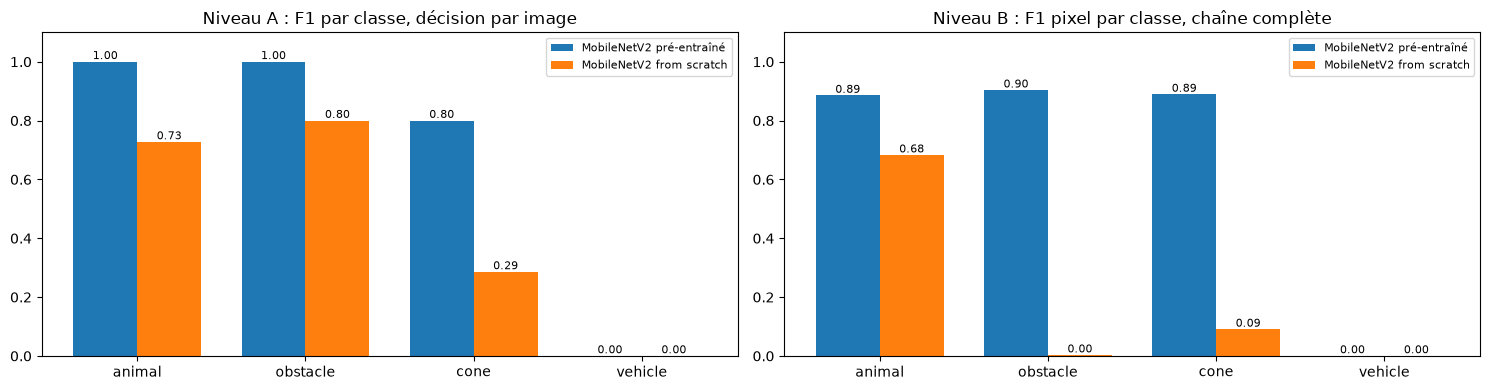

In [5]:
fig, axes = plt.subplots(1, 2 if HAS_LOC else 1, figsize=(15 if HAS_LOC else 8, 4), squeeze=False)
x = np.arange(4); wdt = 0.38
for i, k in enumerate(RUNS):
    b = axes[0, 0].bar(x + (i - 0.5) * wdt, [A_RES[k][f"f1_image_{c}"] for c in OBJ_CLASSES], wdt, label=NAMES[k]); axes[0, 0].bar_label(b, fmt="%.2f", fontsize=8)
    if HAS_LOC:
        b = axes[0, 1].bar(x + (i - 0.5) * wdt, [B_RES[k][f"f1_{c}"] for c in OBJ_CLASSES], wdt, label=NAMES[k]); axes[0, 1].bar_label(b, fmt="%.2f", fontsize=8)
axes[0, 0].set_title("Niveau A : F1 par classe, décision par image")
if HAS_LOC:
    axes[0, 1].set_title("Niveau B : F1 pixel par classe, chaîne complète")
for a in axes[0]:
    a.set_xticks(x); a.set_xticklabels(OBJ_CLASSES); a.set_ylim(0, 1.1); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "f1_par_classe.png"), dpi=110, bbox_inches="tight"); plt.show()

#### Interprétation
- Le pré-entraîné atteint un **F1 pixel de 0,885 à 0,903** sur animal, obstacle et cone dans la chaîne complète (0,89 en moyenne sur ces trois classes).
- Le from scratch ne reconnaît correctement que les animaux (0,683) ; obstacle (0,003) et cone (0,090) sont presque entièrement confondus.
- **Vehicle reste à 0 pour les deux modèles** : avec une seule région d'entraînement, cette classe ne peut pas être apprise. C'est la principale limite des données, pas du modèle.

## 4. Décision par image, côte à côte

Classe annoncée pour chacune des 12 images du test ; ✗ signale une erreur.

In [6]:
dec = pd.DataFrame({"vraie classe": [CLASSES[CLS_OF[n]] for n in test_names]}, index=test_names)
def lab_(p, n):
    return (CLASSES[p] if p else "rien") + ("" if p == CLS_OF[n] else "  ✗")
for k in RUNS:
    dec[NAMES[k] + " · A"] = [lab_(p, n) for n, p in zip(A_TAB[k]["name"], A_TAB[k]["predite"])]
    if HAS_LOC:
        dec[NAMES[k] + " · B"] = [lab_(p, n) for n, p in zip(B_TAB[k]["name"], B_TAB[k]["predite"])]
display(dec); dec.to_csv(os.path.join(OUT_DIR, "decision_par_image.csv"))

,vraie classe,MobileNetV2 pré-entraîné · A,MobileNetV2 pré-entraîné · B,MobileNetV2 from scratch · A,MobileNetV2 from scratch · B
animals12_Collared_Peccary_crossing_the_road,animal,animal,animal,animal,animal
animals13_jeune_bovin_sur_la_route,animal,animal,animal,animal,animal
animals14_Dekemhare_Road,animal,animal,animal,cone ✗,cone ✗
animals19_Porte_de_Roubaix,animal,animal,animal,cone ✗,cone ✗
animals26_Unnamed_Road_Kazakhstan,animal,animal,animal,animal,animal
animals30,animal,animal,animal,animal,animal
cones04_Federation,cone,cone,cone,cone,cone
cones07,cone,cone,cone,animal ✗,animal ✗
obstacles04_cardboard_czech_hedgehog,obstacle,obstacle,obstacle,cone ✗,cone ✗
obstacles09_boulder3,obstacle,obstacle,obstacle,obstacle,animal ✗


#### Interprétation
- **Pré-entraîné : une seule erreur, `vehicle02`**, aux deux niveaux. L'engin de chantier n'est pas détecté par le U-Net (niveau B) et, même avec le masque annoté (niveau A), la région de l'engin est classée « cone ». Les trois cônes de l'image sont, eux, correctement reconnus.
- **From scratch : 5 erreurs au niveau A et 7 au niveau B** (`animals14`, `animals19`, `cones07`, `obstacles04`, `obstacles09`, `obstacles11`, `vehicle02`).

## 5. Taille et temps d'inférence (CPU)

- **Classifieur seul** : un recadrage 224×224.
- **Chaîne complète** : une image, de l'entrée à la carte de classes 1280×720 (U-Net + régions + classification de chaque région), moyenne sur les 12 images du test.

In [7]:
crop0 = C.crop_square(CACHE[test_names[0]][0], C.square_box(REG_TEST[0]["bbox"]))
rows = []
for k in RUNS:
    ms_crop = C.time_inference(lambda: C.classify_crops(MODELS[k], [crop0]))
    row = {"modèle": NAMES[k], "paramètres (M)": C.n_params(MODELS[k]) / 1e6, "fichier .pt (Mo)": os.path.getsize(PT[k]) / 1e6, "ms / recadrage": ms_crop}
    if HAS_LOC:
        thr = CFG[k]["niveau_B"]["threshold"]
        row["ms / image (chaîne)"] = np.mean([C.time_inference(lambda: C.pipeline_maps(C.unet_probs(loc, [n], CACHE), MODELS[k], [n], CACHE, thr), n_warm=2, n_rep=5)
                                              for n in test_names])
    rows.append(row)
size_tab = pd.DataFrame(rows).set_index("modèle").round(1)
if HAS_LOC:
    t_loc = np.mean([C.time_inference(lambda: C.unet_probs(loc, [n], CACHE), n_warm=2, n_rep=5) for n in test_names])
    print(f"Dont U-Net de localisation seul : {t_loc:.0f} ms / image ({C.n_params(loc) / 1e6:.1f} M paramètres)")
display(size_tab); size_tab.to_csv(os.path.join(OUT_DIR, "taille_et_temps.csv"))

Dont U-Net de localisation seul : 192 ms / image (24.4 M paramètres)


,paramètres (M),fichier .pt (Mo),ms / recadrage,ms / image (chaîne)
modèle,,,,
MobileNetV2 pré-entraîné,2.2,9.2,17.2,253.1
MobileNetV2 from scratch,2.2,9.2,14.9,230.1


#### Interprétation
- Les deux modèles ont la même taille : **2,2 M paramètres, 9,2 Mo**, soit environ 5 fois moins que ResNet18 (11,2 M).
- La classification d'une région prend **environ 15 à 17 ms** sur CPU ; la chaîne complète est dominée par le U-Net de localisation (environ 190 ms par image).
- Dans l'application, la localisation du BO1 étant déjà calculée, **le BO2 n'ajoute qu'environ 15 ms par région détectée.**
- Les temps varient avec la charge de la machine : seules les comparaisons entre modèles sont significatives.

## 6. Comparaison avec l'autre approche BO2 de l'équipe (optionnelle)

L'équipe a aussi traité le BO2 avec `bo2_classification.py` : un **ResNet18 pré-entraîné** et un **CNN simple from scratch**, qui classent **une boîte englobante par image**. Si ce fichier et ses poids (`outputs_bo2/bo2_resnet18_best.pt`, `outputs_bo2/bo2_scratch_best.pt`) sont présents, cette section les évalue **avec leur propre code, sans le modifier** :
- niveau A : leur jeu de test sur les masques annotés (`AnomalyDataset`) ;
- niveau B : leur fonction `classify_image` (U-Net du BO1, seuil par défaut 0,27).

Les classes sont identiques et dans le même ordre. La comparaison se fait au **niveau image** (une classe par image), seule mesure commune aux deux approches. Si les fichiers sont absents, la section est sautée.

In [8]:
GH = {}
gh_file = D("bo2_classification.py")
gh_pts = {"ResNet18 pré-entraîné (bo2_classification)": ("resnet18", D("outputs_bo2", "bo2_resnet18_best.pt")),
          "CNN simple from scratch (bo2_classification)": ("scratch", D("outputs_bo2", "bo2_scratch_best.pt"))}
if os.path.exists(gh_file) and any(os.path.exists(p) for _, p in gh_pts.values()):
    sys.path.insert(0, C.ROOT)
    gh = importlib.import_module("bo2_classification")
    from pathlib import Path
    for label, (name, path) in gh_pts.items():
        if not os.path.exists(path):
            print("Absent :", path); continue
        model = gh.build_model(name, pretrained=False)
        model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=False)["state_dict"]); model = model.to(DEVICE).eval()
        ds = gh.AnomalyDataset(Path(C.FRAMES), Path(C.ROOT) / "split.csv", "test", training=False)
        pred_a = [int(model(ds[i][0].unsqueeze(0).to(DEVICE)).argmax(1).item()) + 1 for i in range(len(ds))]
        names_a = ds.rows["name"].tolist()
        row = {"A : images bien classées": float(np.mean([p == CLS_OF[n] for n, p in zip(names_a, pred_a)])),
               "A : macro-F1 image": float(f1_score([CLS_OF[n] for n in names_a], pred_a, labels=sorted({CLS_OF[n] for n in names_a}), average="macro", zero_division=0)),
               "paramètres (M)": C.n_params(model) / 1e6}
        dec[label + " · A"] = [lab_(p, n) for n, p in zip(names_a, pred_a)] if names_a == test_names else None
        if HAS_LOC:
            pred_b = []
            for n in test_names:
                try:
                    cls, _ = gh.classify_image(Path(C.FRAMES) / (n + ".webp"), model, loc, torch.device(DEVICE))
                    pred_b.append(CLASSES.index(cls))
                except ValueError:
                    pred_b.append(0)                      # aucun pixel prédit : rien annoncé
            row["B : images bien classées"] = float(np.mean([p == CLS_OF[n] for n, p in zip(test_names, pred_b)]))
            row["B : macro-F1 image"] = float(f1_score([CLS_OF[n] for n in test_names], pred_b, labels=sorted(set(CLS_OF[n] for n in test_names)), average="macro", zero_division=0))
            dec[label + " · B"] = [lab_(p, n) for n, p in zip(test_names, pred_b)]
        GH[label] = row
    rows = {NAMES[k]: {"A : images bien classées": A_RES[k]["accuracy_image"], "A : macro-F1 image": A_RES[k]["macro_f1_image"],
                       "paramètres (M)": C.n_params(MODELS[k]) / 1e6,
                       **({"B : images bien classées": B_RES[k]["accuracy_image"], "B : macro-F1 image": B_RES[k]["macro_f1_image"]} if HAS_LOC else {})}
            for k in RUNS}
    tab_gh = pd.DataFrame({**rows, **GH}).T.round(3)
    display(tab_gh); tab_gh.to_csv(os.path.join(OUT_DIR, "comparaison_approches_bo2.csv"))
    display(dec); dec.to_csv(os.path.join(OUT_DIR, "decision_par_image.csv"))
else:
    print("bo2_classification.py et/ou ses poids (outputs_bo2/*.pt) absents : section sautée. "
          "Relancer ce notebook une fois ces fichiers disponibles.")

bo2_classification.py et/ou ses poids (outputs_bo2/*.pt) absents : section sautée. Relancer ce notebook une fois ces fichiers disponibles.


## 7. Conclusion

| Critère | MobileNetV2 pré-entraîné | MobileNetV2 from scratch |
|---|---|---|
| Images bien classées, localisation parfaite | **11/12** | 7/12 |
| Images bien classées, chaîne complète | **11/12** | 5/12 |
| Macro-F1 pixel, chaîne complète | **0,669** | 0,194 |
| Paramètres / fichier | 2,2 M / 9,2 Mo | 2,2 M / 9,2 Mo |

1. **Le pré-entraînement ImageNet est décisif** pour reconnaître le type d'objet avec 36 images d'entraînement : à architecture égale, il fait passer la chaîne complète de 5 à 11 images bien classées.
2. **Le MobileNetV2 pré-entraîné est retenu pour l'application** : léger (2,2 M paramètres), rapide (environ 15 ms par région) et sans erreur de type sur les pixels qu'il reçoit.
3. **Limites** : la classe vehicle ne peut pas être apprise (une seule région d'entraînement) ; le test ne compte que 12 images ; les erreurs restantes viennent de la localisation du BO1 (objets lointains, engin non détecté).
4. **Pistes** : ajouter des images de véhicules, introduire un rejet « objet inconnu » sur la confiance du classifieur, et relancer la section 6 dès que les poids de l'autre approche BO2 sont disponibles.

## 8. Sauvegarde des résultats

In [9]:
out = {"niveau_A_test": {NAMES[k]: A_RES[k] for k in RUNS},
       "niveau_B_test": {NAMES[k]: B_RES[k] for k in RUNS} if HAS_LOC else None,
       "baseline_classe_majoritaire": B_RES.get("maj"),
       "taille_temps": size_tab.reset_index().to_dict(orient="records"),
       "approche_bo2_classification": GH or None}
with open(os.path.join(OUT_DIR, "comparaison_bo2.json"), "w", encoding="utf-8") as f:
    json.dump(out, f, indent=1, ensure_ascii=False)
print("Résultats enregistrés dans", os.path.basename(OUT_DIR))

Résultats enregistrés dans outputs_bo2_mobilenetv2_comparaison
